<a href="https://colab.research.google.com/github/nastanelina143-dot/ecommerce-sales-analysis/blob/main/E-commerce_Sales_and_User_Behavior_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install --upgrade google-cloud-bigquery

In [5]:
from google.colab import auth
from google.cloud import bigquery
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, spearmanr, mannwhitneyu, kruskal, wilcoxon
import statsmodels.api as sm

In [6]:
auth.authenticate_user()

In [7]:
client = bigquery.Client(project="data-analytics-mate")


In [8]:
query = """
SELECT
    s.date,
    sp.ga_session_id as session_id,
    case when sp.continent = "(not set)" then "Unknown" else sp.continent end as continent,
    case when sp.country = "(not set)" then "Unknown" else sp.country end as country,
    sp.device,
    case when sp.browser = "<Other>" then "Other" else sp.browser end as browser,
    case when sp.mobile_model_name = "<Other>" then "Other" else sp.mobile_model_name end as mobile_model_name,
    case when sp.operating_system = "<Other>" then "Other" else sp.operating_system end as operating_system,
    case when sp.language is null then 'Unknown' else sp.language end as browser_language,
    case when sp.name = "(organic)" then "Organic"
    when sp.name = "(direct)" then "Direct"
    when sp.name = "<Other>" then "Other"
    when sp.name = "(referral)" then "Referral"
    when sp.name = "(data deleted)" then "Data deleted" else sp.name end as traffic_source,
    case when sp.channel = "Undefined" then "Other" else sp.channel end as channel,
    case when a.id is null then "Guest" else cast(a.id as string) end as registered_user_id,
    case when a.is_verified = 0 then "No"
    when a.is_verified = 1 then "Yes" else "No info" end as is_verified,
    case when a.is_unsubscribed = 0 then "No"
    when a.is_unsubscribed = 1 then "Yes" else "No info" end as is_unsubscribed,
    case when p.category is null then "Unknown" else p.category end as product_category,
    case when p.name is null then "Unknown" else p.name end as product_name,
    p.price as product_price,
    case when p.short_description is null then "Unknown" else p.short_description end as product_description

FROM `data-analytics-mate.DA.session_params` sp
join `data-analytics-mate.DA.session` s
using(ga_session_id)
left join `data-analytics-mate.DA.account_session` ac
on ac.ga_session_id = s.ga_session_id
left join `data-analytics-mate.DA.account` a
on a.id = ac.account_id
left join `data-analytics-mate.DA.order` o
on o.ga_session_id = s.ga_session_id
left join `data-analytics-mate.DA.product` p
on p.item_id = o.item_id
"""

During the SQL coding phase, minimal formatting was applied to the data to make it more aesthetically pleasing. Unspecified countries and continents were grouped as “unknown”, the < Other > category was changed to “Other”, "Undefined" in Channel columns was changed to "Other" as well. Parentheses were removed from the “traffic_source” column. Verified profiles were marked as “No” instead of “0,” and unverified profiles as “Yes” instead of “1.” Following the same logic, the “is_unsubscribed” column was updated accordingly. All missing values in registered_user_id, is_verified, is_unsubscribed, product_category, product_name and product_description columns were grouped as "Guest", "No info" and "Unknown" respectively, but product_price wasn't due to further calculations.

In [9]:
query_job = client.query(query)
results = query_job.result()

In [10]:
df = results.to_dataframe()

#General Description

In [11]:
df.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,browser_language,traffic_source,channel,registered_user_id,is_verified,is_unsubscribed,product_category,product_name,product_price,product_description
0,2021-01-19,7268004754,Unknown,Unknown,desktop,Chrome,Chrome,Web,en-gb,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
1,2021-01-06,8321293308,Unknown,Unknown,desktop,Chrome,Chrome,Web,Unknown,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
2,2020-11-05,4392362373,Unknown,Unknown,desktop,Chrome,Chrome,Web,Unknown,Organic,Organic Search,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
3,2020-12-09,140108698,Unknown,Unknown,desktop,Chrome,Safari,Web,en-us,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
4,2020-11-10,8351127264,Unknown,Unknown,mobile,Safari,iPhone,Web,en-us,Organic,Organic Search,Guest,No info,No info,Unknown,Unknown,NaN,Unknown


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date                 349545 non-null  dbdate 
 1   session_id           349545 non-null  Int64  
 2   continent            349545 non-null  object 
 3   country              349545 non-null  object 
 4   device               349545 non-null  object 
 5   browser              349545 non-null  object 
 6   mobile_model_name    349545 non-null  object 
 7   operating_system     349545 non-null  object 
 8   browser_language     349545 non-null  object 
 9   traffic_source       349545 non-null  object 
 10  channel              349545 non-null  object 
 11  registered_user_id   349545 non-null  object 
 12  is_verified          349545 non-null  object 
 13  is_unsubscribed      349545 non-null  object 
 14  product_category     349545 non-null  object 
 15  product_name     

In [13]:
print(f"Total amount of unique sessions: {df['session_id'].nunique()}")
print(f"One row = one session: {df['session_id'].is_unique}")
print(f"Reviewed period: {np.min(df['date'])} - {np.max(df['date'])}")



Total amount of unique sessions: 349545
One row = one session: True
Reviewed period: 2020-11-01 - 2021-01-31


In [14]:
df['date'] = pd.to_datetime(df['date'])

In [15]:
df.nunique()

,0
date,92
session_id,349545
continent,6
country,108
device,3
browser,6
mobile_model_name,10
operating_system,6
browser_language,10
traffic_source,5


In [16]:
df['continent'].value_counts()

,count
continent,
Americas,193179
Asia,83113
Europe,65135
Oceania,3703
Africa,3620
Unknown,795


In [17]:
df['country'].value_counts()

,count
country,
United States,153470
India,32763
Canada,25994
United Kingdom,11003
France,6958
...,...
Paraguay,70
Malta,69
Kosovo,68


In [18]:
print(df['country'].duplicated().sum())
print(df['country'].str.title().str.strip().duplicated().sum())

349437
349437


In [19]:
df['device'].value_counts()

,count
device,
desktop,204429
mobile,137267
tablet,7849


In [20]:
df['browser'].value_counts()

,count
browser,
Chrome,238460
Safari,83254
Other,8930
Edge,8023
Firefox,6433
Android Webview,4445


In [21]:
df['mobile_model_name'].value_counts()

,count
mobile_model_name,
Chrome,97254
iPhone,71326
Safari,70891
Other,70839
ChromeBook,19084
Edge,7907
iPad,5090
Firefox,4874
Pixel 4 XL,1246


In [22]:
df['operating_system'].value_counts()

,count
operating_system,
Web,203909
Windows,40937
iOS,40102
Android,29808
Macintosh,26116
Other,8673


In [23]:
df['browser_language'].value_counts()

,count
browser_language,
en-us,159893
Unknown,114266
en-gb,24774
zh,12222
en,11518
en-ca,9332
es-es,5760
fr,5652
de,3387


In [24]:
df['traffic_source'].value_counts()

,count
traffic_source,
Organic,119024
Direct,81382
Other,66289
Referral,61436
Data deleted,21414


In [25]:
df['channel'].value_counts()

,count
channel,
Organic Search,124425
Paid Search,94341
Direct,81382
Social Search,27914
Other,21483


In [26]:
print(f"Total amount of unique registered users: {df['registered_user_id'].nunique()}")

Total amount of unique registered users: 27946


In [27]:
df['is_verified'].value_counts()

,count
is_verified,
No info,321600
Yes,20036
No,7909


In [28]:
df['is_unsubscribed'].value_counts()

,count
is_unsubscribed,
No info,321600
No,23210
Yes,4735


In [29]:
df['product_category'].value_counts()

,count
product_category,
Unknown,316007
Bookcases & shelving units,7630
Chairs,5952
Sofas & armchairs,4301
Tables & desks,2941
Beds,2926
Cabinets & cupboards,2318
Outdoor furniture,2229
Children's furniture,1702


In [30]:
df['product_name'].value_counts()

,count
product_name,
Unknown,316007
BESTÅ,1257
GRÖNLID,915
TROFAST,813
IVAR,754
...,...
LUBBAN,5
BYLLAN,4
NILSOVE / NORNA,4


In [31]:
print(df['product_name'].duplicated().sum())
print(df['product_name'].str.title().str.strip().duplicated().sum())

348994
348994


In [32]:
df['product_description'].value_counts()

,count
product_description,
Unknown,316007
Chair,659
Armchair,382
3-seat sofa,333
3-seat sofa-bed,286
...,...
Cover for footstool module,3
"Frame/wire baskets/top shelves, 148x51x104 cm",3
"Drawer unit on castors, 45x55 cm",3


In [33]:
print(df['product_description'].duplicated().sum())
print(df['product_description'].str.title().str.strip().duplicated().sum())

348068
348068


The dataset covers 92 days (2020-11-01 to 2021-01-31) and contains 349,545 unique sessions. Visitors come from 5 continents and 107 countries, excluding countries and continents marked as "Unknown". They used 3 device types, 6 browsers, 6 operating systems, 10 device models and 9 browser languages. Traffic comes from 4 sources grouped into 5 channels (Organic Search, Paid Search, Social Search, Direct, Other). There are 27,945 registered users, each with two binary flags: is_verified (True means the user confirmed their email, False means they did not) and is_unsubscribed (True means the user unsubscribed, False means they are still subscribed). The product catalog includes 14 categories, 550 product names, 829 distinct prices and 1,476 distinct descriptions. After stripping whitespace and unifying case in the country, product_name and product_description columns, the number of unique values did not change, so there are no hidden duplicates caused by spelling or case.

In [34]:
df['product_price'].describe()

,product_price
count,33538.000000
mean,953.298679
std,1317.001775
min,3.000000
25%,170.000000
50%,445.000000
75%,1195.000000
max,9585.000000


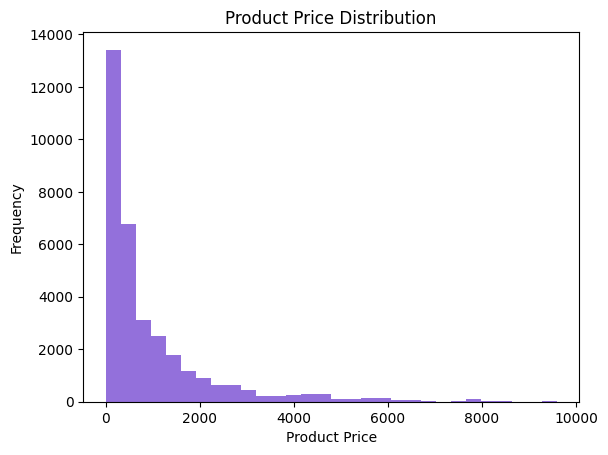

In [35]:
plt.hist(df['product_price'], bins=30, color='mediumpurple')
plt.title("Product Price Distribution")
plt.xlabel("Product Price")
plt.ylabel("Frequency")
plt.show()

The distribution of product prices is strongly right-skewed. Most purchased items are cheap: the histogram peaks in the lowest price range, and the number of purchases falls quickly as the price grows, leaving a long, thin tail of expensive items that reaches almost 9,600. Prices are in a range between a minimum of 3 and a maximum of 9,585. The mean (953) is more than twice the median (445), which is a typical sign of right skew: a small number of expensive products pulls the mean up, while the median better describes a “typical” purchase. The quartiles show the same picture: 25% of purchases cost 170 or less, half cost 445 or less, and 75% cost 1,195 or less. The standard deviation (1,317) is larger than the mean, which means the prices are widely spread and the values vary a lot from item to item.

In [36]:
df.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,browser_language,traffic_source,channel,registered_user_id,is_verified,is_unsubscribed,product_category,product_name,product_price,product_description
0,2021-01-19,7268004754,Unknown,Unknown,desktop,Chrome,Chrome,Web,en-gb,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
1,2021-01-06,8321293308,Unknown,Unknown,desktop,Chrome,Chrome,Web,Unknown,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
2,2020-11-05,4392362373,Unknown,Unknown,desktop,Chrome,Chrome,Web,Unknown,Organic,Organic Search,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
3,2020-12-09,140108698,Unknown,Unknown,desktop,Chrome,Safari,Web,en-us,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
4,2020-11-10,8351127264,Unknown,Unknown,mobile,Safari,iPhone,Web,en-us,Organic,Organic Search,Guest,No info,No info,Unknown,Unknown,NaN,Unknown


In [37]:
print(f"Persentage of unknown continent: {round((df['continent'] == "Unknown").sum() / df.shape[0] * 100, 2)}%")
print(f"Persentage of unknown country: {round((df['country'] == "Unknown").sum() / df.shape[0] * 100, 2)}%")
print(f"Persentage of unknown browser language: {round((df['browser_language'] == "Unknown").sum() / df.shape[0] * 100, 2)}%")
print(f"Persentage of not registered users: {round((df['registered_user_id'] == "Guest").sum() / df.shape[0] * 100, 2)}%")
print(f"Persentage of unknown product category: {round((df['product_category'] == "Unknown").sum() / df.shape[0] * 100, 2)}%")

Persentage of unknown continent: 0.23%
Persentage of unknown country: 0.8%
Persentage of unknown browser language: 32.69%
Persentage of not registered users: 92.01%
Persentage of unknown product category: 90.41%


Several factors could explain why there are so many missing values in this data frame. The missing values in the “registered users” column indicate that, out of all sessions, only a part of users had an account. Additionally, not every user made a purchase, so the product columns are also partially empty. The language column may have been left blank for another reason, such as a technical error during data collection or because the user accessed the site via a device or browser where language settings are not transmitted. Proxy servers that mask the user's actual location could explain why there are unknown values for countries and continents.

#Sales Analysis

To show sales from two angles, we use two metrics. In the first part of the analysis (rankings and sales dynamics), sales are measured as revenue, the sum of product prices: it shows how much money each market, category or channel brings. In the pivot tables and the following sections, sales are measured as the number of orders (items sold): it shows how often customers buy, regardless of price. Revenue reflects the monetary value of sales, while the number of orders reflects purchase activity, so together they give a more complete picture. Each chart and table is labeled with the metric it uses.

##Top-5 countries by revenue and items sold

In [38]:
plt.style.use('ggplot')

In [39]:
groupby_countries = df.groupby('country')['product_price'].agg(['sum', 'count']).sort_values(by='sum', ascending=False).head(5).reset_index()
groupby_countries['sum'] = groupby_countries['sum'] / 1000000

In [40]:
groupby_countries

,country,sum,count
0,United States,13.943554,14673
1,India,2.809762,3029
2,Canada,2.437921,2560
3,United Kingdom,0.938318,1029
4,France,0.710693,678


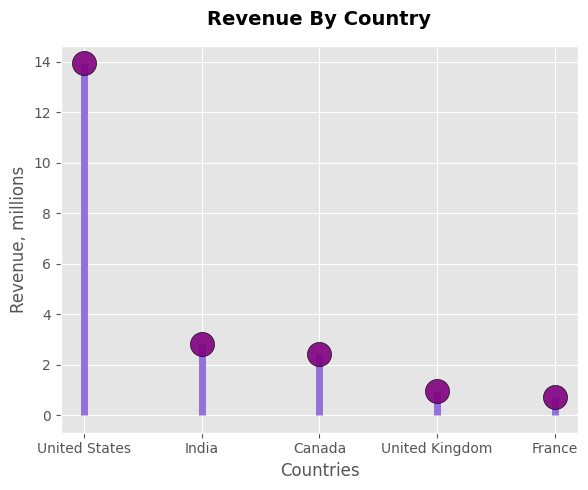

In [41]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.vlines(x=groupby_countries['country'], ymin=0, ymax=groupby_countries['sum'], color='mediumpurple', linewidth=5)

ax.scatter(groupby_countries['country'], groupby_countries['sum'], color='purple', alpha=0.9, edgecolors="black", zorder=3, s=300)

ax.set_title("Revenue By Country", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Countries")
ax.set_ylabel("Revenue, millions")

plt.tight_layout()
plt.show()

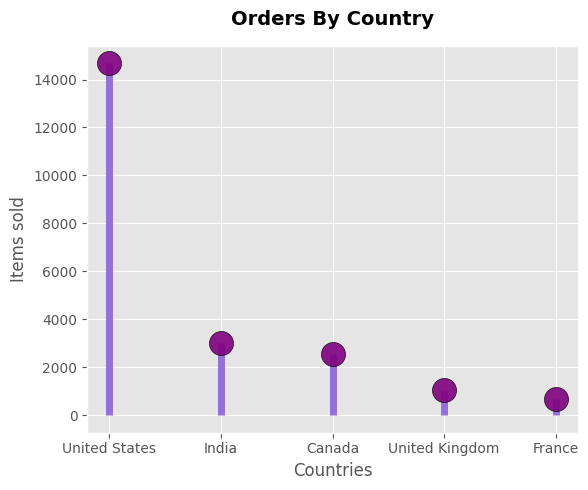

In [42]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.vlines(x=groupby_countries['country'], ymin=0, ymax=groupby_countries['count'], color='mediumpurple', linewidth=5)

ax.scatter(groupby_countries['country'], groupby_countries['count'], color='purple', alpha=0.9, edgecolors="black", zorder=3, s=300)

ax.set_title("Orders By Country", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Countries")
ax.set_ylabel("Items sold")

plt.tight_layout()
plt.show()

The United States is the clear leader among the top-5 countries, both in revenue (about 14M) and in the number of orders (more then 14,000). Its result is several times higher than that of any other country: India and Canada follow with roughly 2.5-3M in revenue and 2,500-3,000 orders each, while the United Kingdom and France bring only about 1M and 0.7M.

##Top-3 continents by revenue and items sold

In [43]:
groupby_continents = df.groupby('continent')['product_price'].agg(['sum', 'count']).sort_values(by='sum', ascending=False).head(3).reset_index()
groupby_continents['sum'] = groupby_continents['sum'] / 1000000
groupby_continents

,continent,sum,count
0,Americas,17.665280,18553
1,Asia,7.601298,7950
2,Europe,5.934624,6261


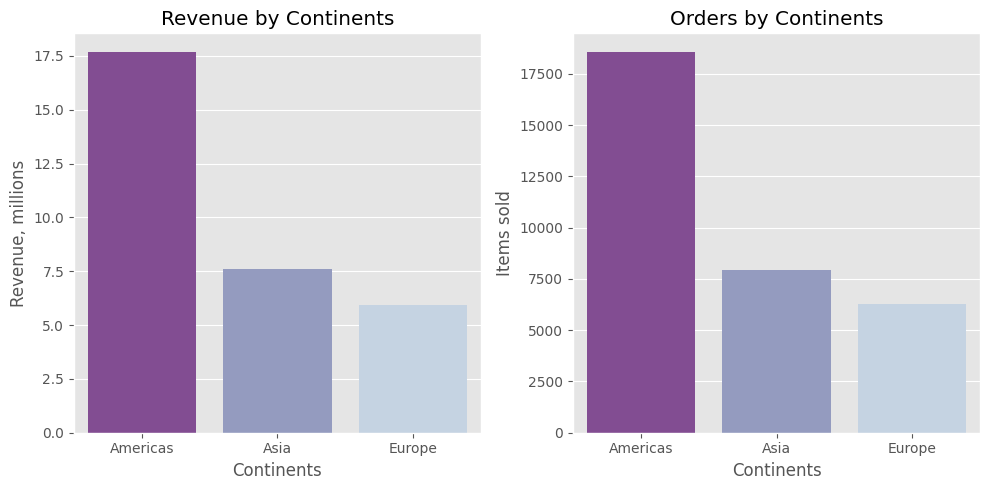

In [44]:

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.barplot(data=groupby_continents, x='continent', y='sum', palette='BuPu_r', ax=ax[0], hue='continent', legend=False)

ax[0].set_title("Revenue by Continents")
ax[0].set_xlabel("Continents")
ax[0].set_ylabel("Revenue, millions")

sns.barplot(data=groupby_continents, x='continent', y='count', palette='BuPu_r', ax=ax[1], hue='continent', legend=False)

ax[1].set_title("Orders by Continents")
ax[1].set_xlabel("Continents")
ax[1].set_ylabel("Items sold")

plt.tight_layout()
plt.show()

The Americas are the clear leader among the top-3 continents, both in revenue (about 17.7M) and in the number of items sold (about 18,500). Asia is second with roughly 7.6M and 7,950 items, and Europe is third with about 5.9M and 6,260 items. The Americas generate more than twice as much revenue as Asia and about three times as much as Europe.

##Top-10 categories by Revenue

In [45]:
groupby_category = df[df['product_category'] != "Unknown"].groupby('product_category')['product_price'].sum().sort_values(ascending=False).head(10).reset_index()
groupby_category['product_price'] = groupby_category['product_price'] / 1000000
groupby_category

,product_category,product_price
0,Sofas & armchairs,8.388255
1,Chairs,6.147749
2,Beds,4.919725
3,Bookcases & shelving units,3.640818
4,Cabinets & cupboards,2.336499
5,Outdoor furniture,2.142222
6,Tables & desks,1.790307
7,Chests of drawers & drawer units,0.906563
8,Bar furniture,0.735503
9,Children's furniture,0.467697


"Unknown" product category was removed from the calculation because "Unknown" product category means there is no purchases.

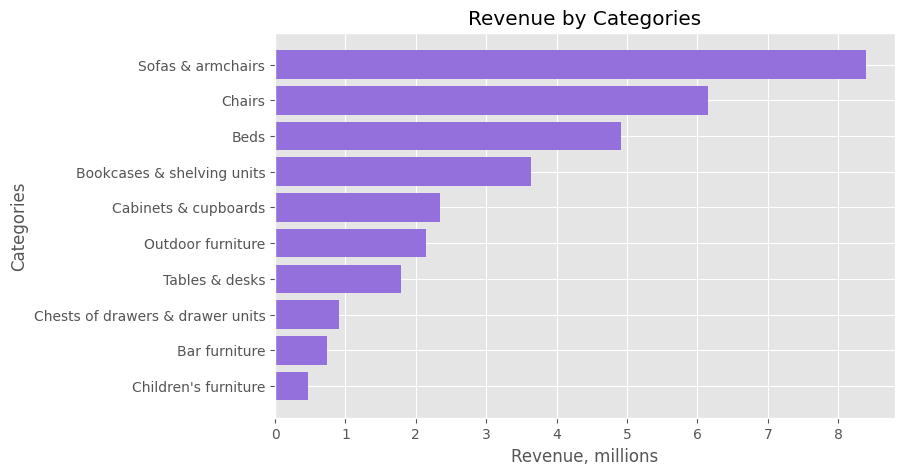

In [46]:
plt.figure(figsize=(8, 5))
plt.barh(groupby_category['product_category'], groupby_category['product_price'], color="mediumpurple")
plt.title("Revenue by Categories")
plt.xlabel("Revenue, millions")
plt.ylabel("Categories")
plt.gca().invert_yaxis()
plt.show()

The horizontal bar chart titled “Revenue by Categories” clearly shows the dominance of the “Sofas & armchairs” and “Chairs” categories, which generate the highest revenue, exceeding 8 million and 6 million respectively. The “Beds” and “Bookcases & shelving units” categories also show significant figures. At the same time, the items at the bottom of the list—specifically “Chests of drawers & drawer units,” “Bar furniture,” and “Children's furniture”—generate the least revenue, with figures below 1 million.

##Items sold by Device Types, Mobile Models, Operating Systems, Browsers and Channels

In [47]:
groupby_device = df.groupby('device')['product_price'].count().sort_values(ascending=False).reset_index()
groupby_device

,device,product_price
0,desktop,19702
1,mobile,13113
2,tablet,723


In [48]:
groupby_op_sys = df.groupby('operating_system')['product_price'].count().sort_values(ascending=False).reset_index()
groupby_op_sys

,operating_system,product_price
0,Web,19537
1,Windows,3896
2,iOS,3798
3,Android,2852
4,Macintosh,2573
5,Other,882


In [49]:
groupby_brow = df.groupby('browser')['product_price'].count().sort_values(ascending=False).reset_index()
groupby_brow

,browser,product_price
0,Chrome,23015
1,Safari,7903
2,Other,865
3,Edge,752
4,Firefox,583
5,Android Webview,420


In [50]:
groupby_chan = df.groupby('channel')['product_price'].count().sort_values(ascending=False).reset_index()
groupby_chan

,channel,product_price
0,Organic Search,11921
1,Paid Search,9042
2,Direct,7800
3,Social Search,2716
4,Other,2059


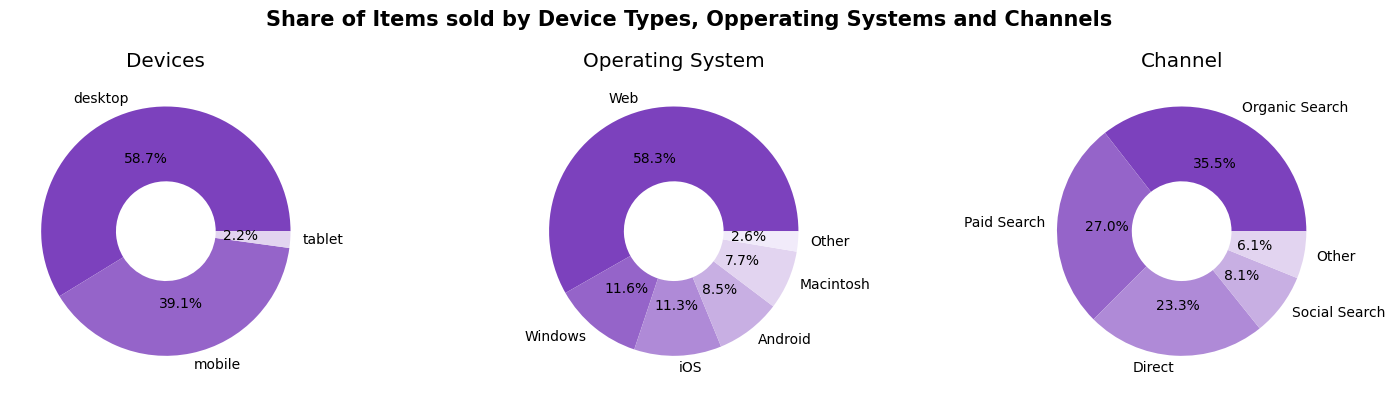

In [51]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Share of Items sold by Device Types, Opperating Systems and Channels', fontsize=15, fontweight='semibold')
ax[0].pie(
    groupby_device['product_price'],
    labels=groupby_device['device'],
    autopct='%1.1f%%',
    wedgeprops={'width': 0.6},
    colors=['#7C41BD', '#9564C9', '#E2D4F0'])
ax[0].set_title('Devices')

ax[1].pie(
    groupby_op_sys['product_price'],
    labels=groupby_op_sys['operating_system'],
    autopct='%1.1f%%',
    wedgeprops={'width': 0.6},
    colors=['#7C41BD', '#9564C9', '#AF8AD7', '#C8AFE3', '#E2D4F0', '#F1EBFA'])
ax[1].set_title('Operating System')


ax[2].pie(
    groupby_chan['product_price'],
    labels=groupby_chan['channel'],
    autopct='%1.1f%%',
    wedgeprops={'width': 0.6},
    colors=['#7C41BD', '#9564C9', '#AF8AD7', '#C8AFE3', '#E2D4F0'])
ax[2].set_title('Channel')

plt.tight_layout()
plt.show()

An analysis of the sales structure shows a clear dominance of desktop devices, which account for more than half of the market (58.7%), leaving mobile phones with 39.1% and tablets with a significantly smaller share of 2.2%. In terms of operating systems, the Web platform dominates with a 58.3% share, while Windows, iOS, and Android account for between 8.5% and 11.6% of sales. The main traffic sources are Organic Search (35.5%), Paid Search (27.0%), and Direct (23.3%), confirming the high effectiveness of search engine optimization and paid advertising campaigns in driving overall sales.

In [52]:
groupby_model = df.groupby('mobile_model_name')['product_price'].count().sort_values(ascending=False).reset_index()
groupby_model


,mobile_model_name,product_price
0,Chrome,9359
1,Safari,6833
2,iPhone,6819
3,Other,6801
4,ChromeBook,1877
5,Edge,741
6,iPad,456
7,Firefox,430
8,Pixel 4 XL,117
9,Pixel 3,105


In [53]:
groupby_browser = df.groupby('browser')['product_price'].count().sort_values(ascending=False).reset_index()
groupby_browser

,browser,product_price
0,Chrome,23015
1,Safari,7903
2,Other,865
3,Edge,752
4,Firefox,583
5,Android Webview,420


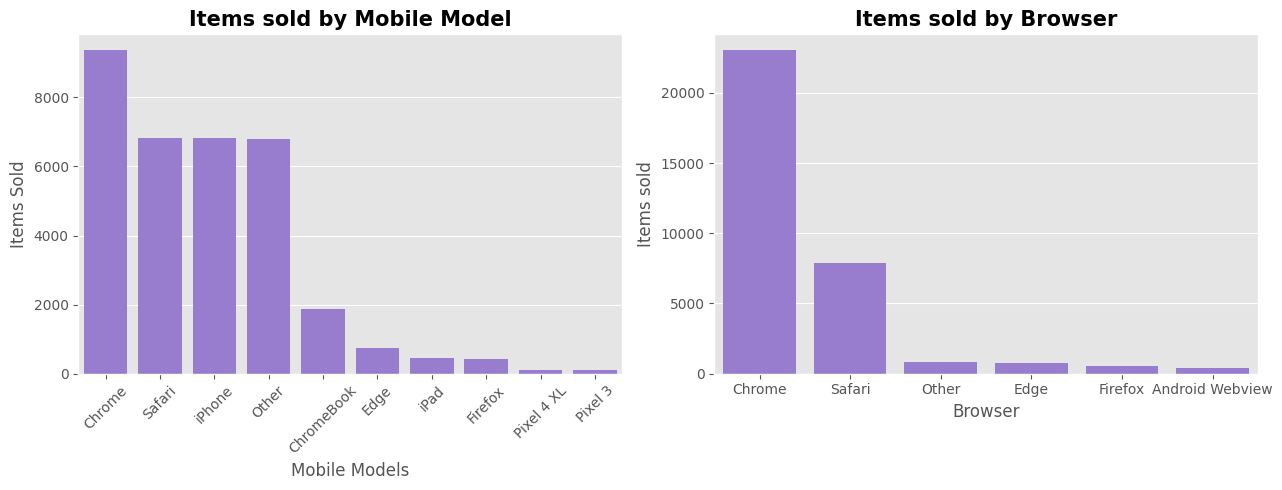

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(13,5))

sns.barplot(data=groupby_model, x='mobile_model_name', y='product_price', color='mediumpurple', ax=ax[0])

ax[0].set_title("Items sold by Mobile Model", fontsize=15, fontweight='semibold')
ax[0].set_xlabel("Mobile Models")
ax[0].set_ylabel("Items Sold")
ax[0].tick_params(axis='x', rotation=45)

sns.barplot(data=groupby_browser, x='browser', y='product_price', color='mediumpurple', ax=ax[1])

ax[1].set_title("Items sold by Browser", fontsize=15, fontweight='semibold')
ax[1].set_xlabel("Browser")
ax[1].set_ylabel("Items sold")

plt.tight_layout()
plt.show()

The majority of sales are concentrated in two key segments, where Chrome is the undisputed leader among browsers and mobile devices, leaving its closest competitors far behind. In the mobile device category, Safari, iPhone, and other models consistently share second place in terms of volume, while among browsers, Safari is the only notable alternative, and the share of all other browsers remains virtually negligible. Thus, the user base clearly favors the Chrome ecosystem, making it a priority area for further product optimization and development.

##User Registration & Account Status Overview

In [55]:
registered_count = (df['registered_user_id'] != 'Guest').sum()
registered_verif_count = ((df['registered_user_id'] != 'Guest') & (df['is_verified'] == 'Yes')).sum()
registered_verif_no_count = registered_count - registered_verif_count

registered_unsub_count = ((df['registered_user_id'] != 'Guest') & (df['is_unsubscribed'] == 'Yes')).sum()
registered_sub_count = registered_count - registered_unsub_count
guest_count = (df['registered_user_id'] == 'Guest').sum()

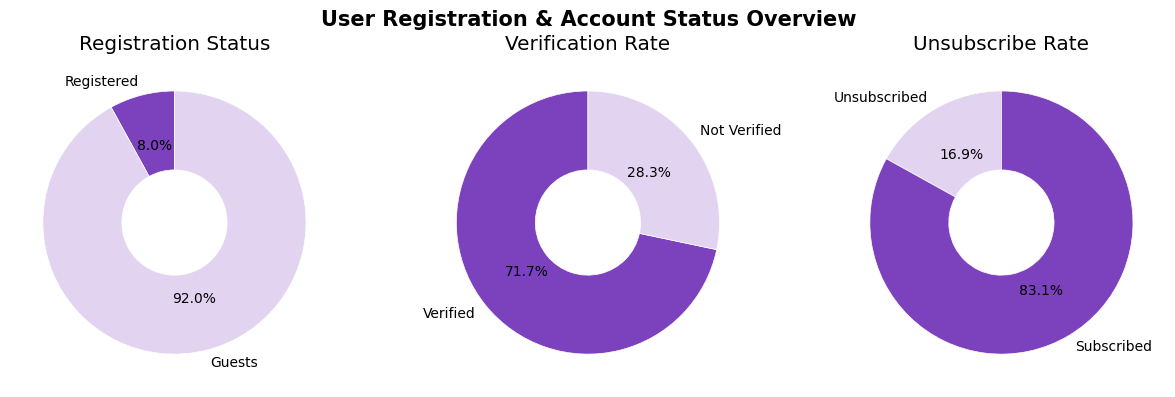

In [56]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle('User Registration & Account Status Overview', fontsize=15, fontweight='semibold')

ax[0].pie([registered_count, guest_count],
          labels=['Registered', 'Guests'], autopct='%1.1f%%',
          startangle=90,
          colors=['#7C41BD', '#E2D4F0'],
          wedgeprops={'width': 0.6, 'edgecolor': 'white'})
ax[0].set_title('Registration Status')

ax[1].pie([registered_verif_count, registered_verif_no_count],
          labels=['Verified', 'Not Verified'], autopct='%1.1f%%',
          startangle=90,
          colors=['#7C41BD', '#E2D4F0'],
          wedgeprops={'width': 0.6, 'edgecolor': 'white'})
ax[1].set_title('Verification Rate')

ax[2].pie([registered_unsub_count, registered_sub_count],
          labels=['Unsubscribed', 'Subscribed'], autopct='%1.1f%%',
          startangle=90,
          colors=['#E2D4F0', '#7C41BD'],
          wedgeprops={'width': 0.6, 'edgecolor': 'white'})
ax[2].set_title('Unsubscribe Rate')

plt.tight_layout()
plt.show()

The majority of web sessions (92.0%) belong to guest users, with registered users accounting for only 8.0% of total activity. Among the registered user base, 71.7% have completed profile verification, while the remaining 28.3% remain unverified. Additionally, 16.9% of registered users have opted to unsubscribe from communications, whereas 83.1% maintain an active subscription status. These metrics highlight a strong verification rate among registered users and a significant opportunity to convert guest traffic into registered accounts.

In [57]:
grby_country = df[df['registered_user_id'] != 'Guest'].groupby('country')['registered_user_id'].count().sort_values(ascending=False).head(5).reset_index()
grby_country

,country,registered_user_id
0,United States,12384
1,India,2687
2,Canada,2067
3,United Kingdom,859
4,France,553


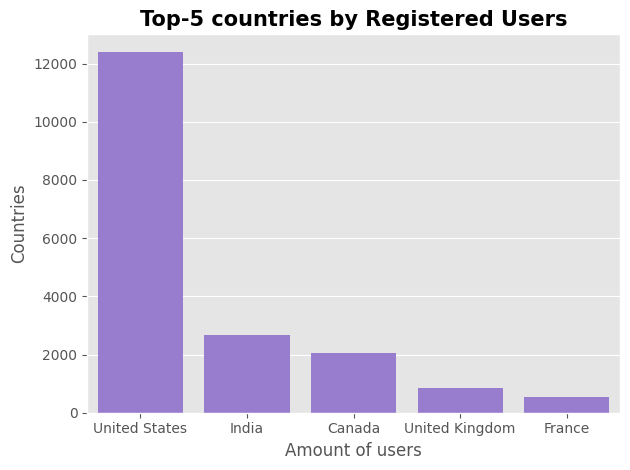

In [58]:
sns.barplot(data=grby_country, x='country', y='registered_user_id', color='mediumpurple')
plt.title("Top-5 countries by Registered Users", fontsize=15, fontweight='semibold')
plt.xlabel("Amount of users")
plt.ylabel("Countries")

plt.tight_layout()
plt.show()

The United States holds a dominant lead in the number of registered users, significantly outperforming all other regions with over 12,000 accounts. India and Canada follow as the second and third largest markets, while the United Kingdom and France represent smaller, secondary shares of the registered user base. This underscores North America as the primary target market for engagement and growth strategies.

#Dynamic Analysis

In [59]:
df.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,browser_language,traffic_source,channel,registered_user_id,is_verified,is_unsubscribed,product_category,product_name,product_price,product_description
0,2021-01-19,7268004754,Unknown,Unknown,desktop,Chrome,Chrome,Web,en-gb,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
1,2021-01-06,8321293308,Unknown,Unknown,desktop,Chrome,Chrome,Web,Unknown,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
2,2020-11-05,4392362373,Unknown,Unknown,desktop,Chrome,Chrome,Web,Unknown,Organic,Organic Search,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
3,2020-12-09,140108698,Unknown,Unknown,desktop,Chrome,Safari,Web,en-us,Direct,Direct,Guest,No info,No info,Unknown,Unknown,NaN,Unknown
4,2020-11-10,8351127264,Unknown,Unknown,mobile,Safari,iPhone,Web,en-us,Organic,Organic Search,Guest,No info,No info,Unknown,Unknown,NaN,Unknown


In [60]:
gp_date = df.groupby('date')['product_price'].sum().reset_index()

In [61]:
gp_date.tail()

,date,product_price
87,2021-01-27,286340.7
88,2021-01-28,0.0
89,2021-01-29,0.0
90,2021-01-30,0.0
91,2021-01-31,0.0


The last four days of the period (2021-01-28 to 2021-01-31) show zero revenue, although the number of sessions stays at a normal level (about 2,800-4,100 per day). This pattern most likely indicates missing purchase data for these dates rather than a real absence of sales. Keeping these days would distort the results of the analysis: they create an artificial drop at the end of every sales dynamics charts and would produce a false common decline across all groups, which inflates the correlations between them. Therefore, these four days are excluded from the calculations. The remaining period contains 88 days.

In [62]:
df_dt = df[df['date'] < '2021-01-28'].copy()

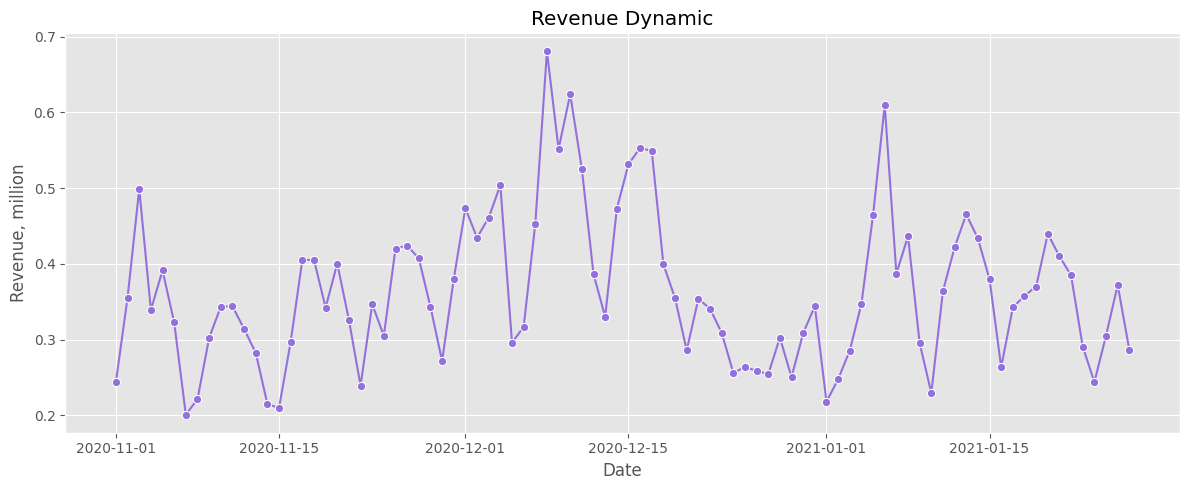

In [63]:
pt = df_dt.pivot_table(index='date', values='product_price', aggfunc='sum', fill_value=0) / 1000000

plt.figure(figsize=(12, 5))
sns.lineplot(x=pt.index, y=pt['product_price'], marker='o', color="mediumpurple")
plt.title('Revenue Dynamic')
plt.xlabel('Date')
plt.ylabel('Revenue, million')

plt.tight_layout()
plt.show()

Daily revenue fluctuates between roughly 0.2M and 0.7M. The highest peak falls in the second half of December, which is likely connected to the pre-holiday shopping season. A second, smaller peak appears in early January.

##By Weekday

In [64]:
df['weekday'] = df['date'].dt.weekday

In [65]:
groupby_weekday = df.groupby('weekday')['product_price'].sum() / 1000000
groupby_weekday

,product_price
weekday,
0,4.636290
1,5.457516
2,5.466543
3,4.936936
4,4.523067
5,3.477991
6,3.473388


In [66]:
groupby_weekday.index = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
groupby_weekday

,product_price
Monday,4.636290
Tuesday,5.457516
Wednesday,5.466543
Thursday,4.936936
Friday,4.523067
Saturday,3.477991
Sunday,3.473388


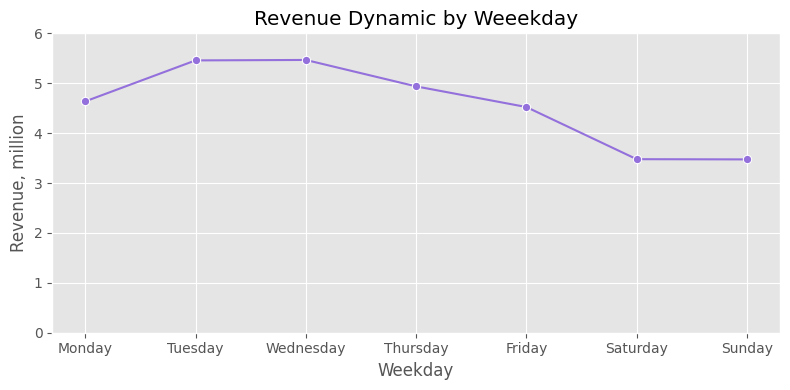

In [67]:
plt.figure(figsize=(8, 4))
sns.lineplot(x=groupby_weekday.index, y=groupby_weekday.values, marker='o', color="mediumpurple")
plt.title('Revenue Dynamic by Weeekday')
plt.xlabel('Weekday')
plt.ylabel('Revenue, million')
plt.ylim(0, 6)
plt.tight_layout()
plt.show()

Revenue shows a clear weekly pattern. Sales are highest on Tuesday and Wednesday, then decline gradually through the end of the week: Thursday is about 4.9M and Friday about 4.5M. The lowest revenue falls on Saturday and Sunday. Monday is slightly lower than Tuesday and Wednesday. This suggests that customers buy mostly on working days, while weekends are the weakest period. Since the data cover only three months, this is evidence of a weekly cycle, not of long-term seasonality.

##By Top-3 Continents (by Revenue)

Since there are 5 continents, displaying all 5 on a single chart could be overwhelming, so for better visual clarity, we'll focus on the top 3 by revenue

In [68]:
groupby_con = df_dt.groupby('continent')['product_price'].sum().sort_values(ascending=False).head(3).reset_index()
top_continents = groupby_con['continent'].tolist()
top_continents

['Americas', 'Asia', 'Europe']

In [69]:
df_top_cn = df_dt[df_dt['continent'].isin(top_continents)]

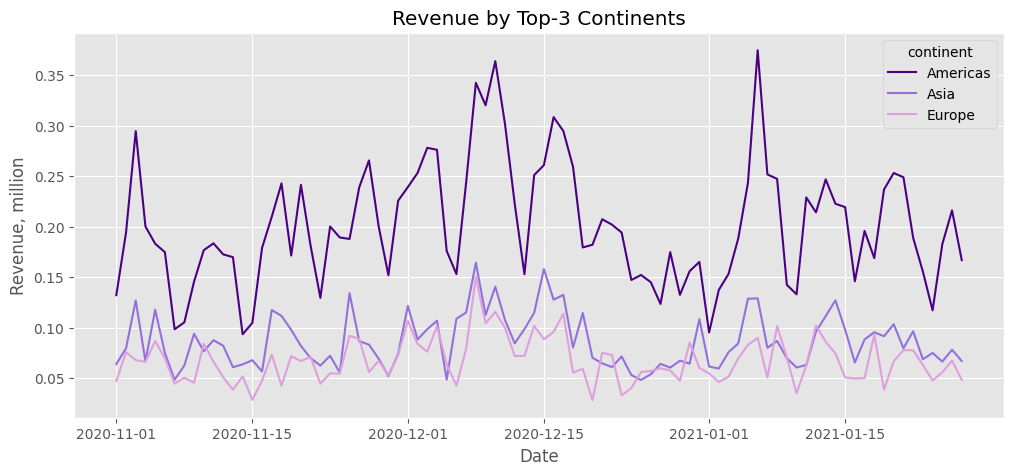

In [70]:
con = df_top_cn.pivot_table(index='date', columns='continent', values='product_price', aggfunc='sum', fill_value=0) / 1000000

plt.figure(figsize=(12, 5))
sns.lineplot(data=con, dashes=False, palette=['indigo', 'mediumpurple', 'plum'])
plt.title('Revenue by Top-3 Continents')
plt.xlabel('Date')
plt.ylabel('Revenue, million')
plt.show()

Americas is the dominant revenue generator throughout the entire period, consistently outperforming other regions with notable sales peaks. Asia holds a stable second place but lags significantly behind Americas. Europe generates the lowest share of revenue among the top three, remaining consistently low.

##By Device

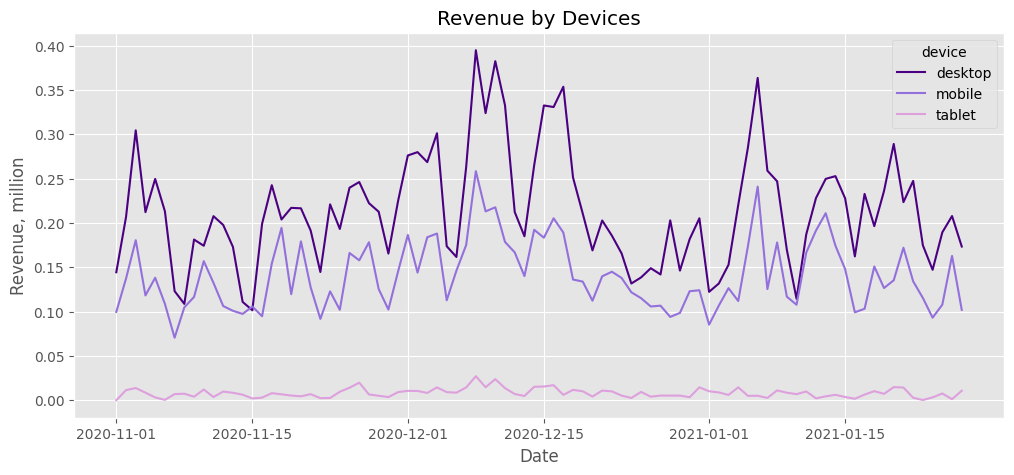

In [71]:
dev = df_dt.pivot_table(index='date', columns='device', values='product_price', aggfunc='sum', fill_value=0) / 1000000

plt.figure(figsize=(12, 5))
sns.lineplot(data=dev, dashes=False, palette=['indigo', 'mediumpurple', 'plum'])
plt.title('Revenue by Devices')
plt.xlabel('Date')
plt.ylabel('Revenue, million')
plt.show()

Desktop users generate the highest share of total revenue throughout the entire period, showing prominent activity peaks. Mobile devices rank second with consistent revenue generation, while tablets contribute a negligible amount to overall sales. Desktop and mobile traffic remain the core revenue drivers for the business.

##By Top-3 Browsers (by Revenue)

Since we have 6 browsers, displaying all 6 on a single chart might be overwhelming, so for better visual clarity, we'll focus on the top 3 by revenue

In [72]:
groupby_brow = df_dt.groupby('browser')['product_price'].sum().sort_values(ascending=False).head(3).reset_index()
top_browser = groupby_brow['browser'].tolist()
top_browser

['Chrome', 'Safari', 'Other']

In [73]:
df_top_br = df_dt[df_dt['browser'].isin(top_browser)]

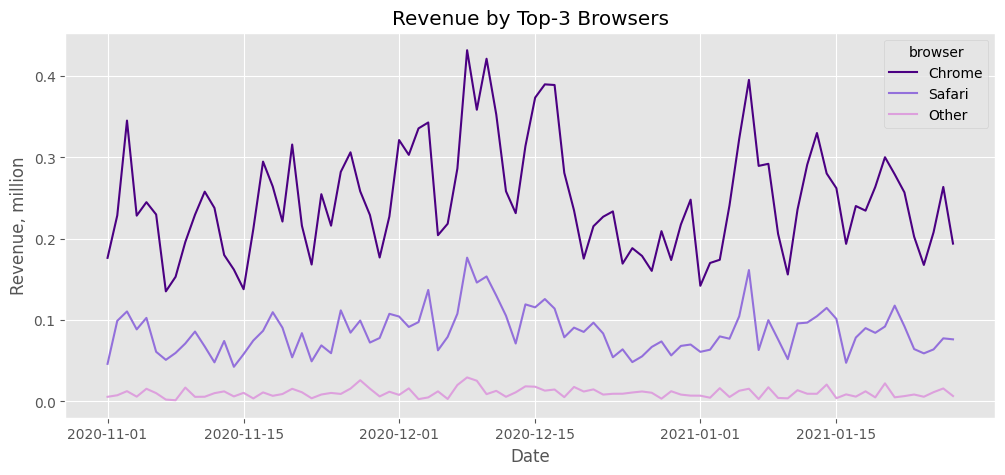

In [74]:
brow = df_top_br.pivot_table(index='date', columns='browser', values='product_price', aggfunc='sum', fill_value=0) / 1000000
brow = brow[['Chrome', 'Safari', 'Other']]

plt.figure(figsize=(12, 5))
sns.lineplot(data=brow, dashes=False, palette=['indigo', 'mediumpurple', 'plum'])
plt.title('Revenue by Top-3 Browsers')
plt.xlabel('Date')
plt.ylabel('Revenue, million')
plt.show()

Chrome is the dominant browser, generating the highest share of revenue with frequent peaks throughout the period. Safari holds the second position with stable, moderate sales contributions, while Other browsers account for the lowest revenue share. Chrome and Safari represent the core platforms for user transactions.

##By Top-3 Operating System (by Revenue)

Since we have 6 operating systems, displaying all 6 on a single chart might be overwhelming, so for better visual clarity, we'll focus on the top 3 by revenue

In [75]:
groupby_op = df_dt.groupby('operating_system')['product_price'].sum().sort_values(ascending=False).head(3).reset_index()
top_op = groupby_op['operating_system'].tolist()
top_op

['Web', 'Windows', 'iOS']

In [76]:
df_top_op = df_dt[df_dt['operating_system'].isin(top_op)]

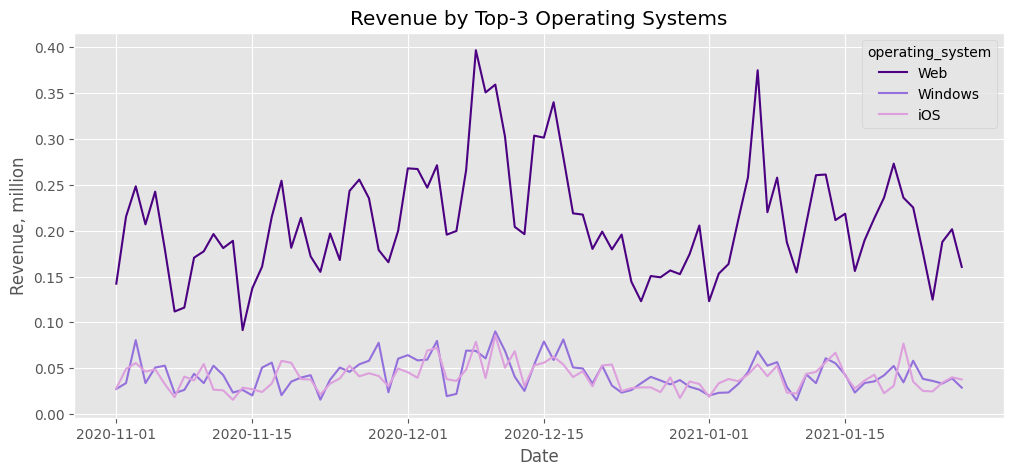

In [77]:
op = df_top_op.pivot_table(index='date', columns='operating_system', values='product_price', aggfunc='sum', fill_value=0) / 1000000

plt.figure(figsize=(12, 5))
sns.lineplot(data=op, dashes=False, palette=['indigo', 'mediumpurple', 'plum'])
plt.title('Revenue by Top-3 Operating Systems')
plt.xlabel('Date')
plt.ylabel('Revenue, million')
plt.show()

The web is the dominant platform, having consistently accounted for the largest share of total revenue throughout the entire period and showing clear peaks in activity. Windows and iOS share second and third place, demonstrating stable but significantly lower revenue levels. The web platform remains the primary driver of commercial performance.

##By Top-3 Traffic Channels (by Revenue)

Since we have 5 traffic channels, displaying all 5 on a single graph might be too much to take in, so for better visual clarity, we'll focus on the top 3 by revenue

In [78]:
groupby_ch = df_dt.groupby('channel')['product_price'].sum().sort_values(ascending=False).head(3).reset_index()
top_ch = groupby_ch['channel'].tolist()
top_ch

['Organic Search', 'Paid Search', 'Direct']

In [79]:
df_top_ch = df_dt[df_dt['channel'].isin(top_ch)]

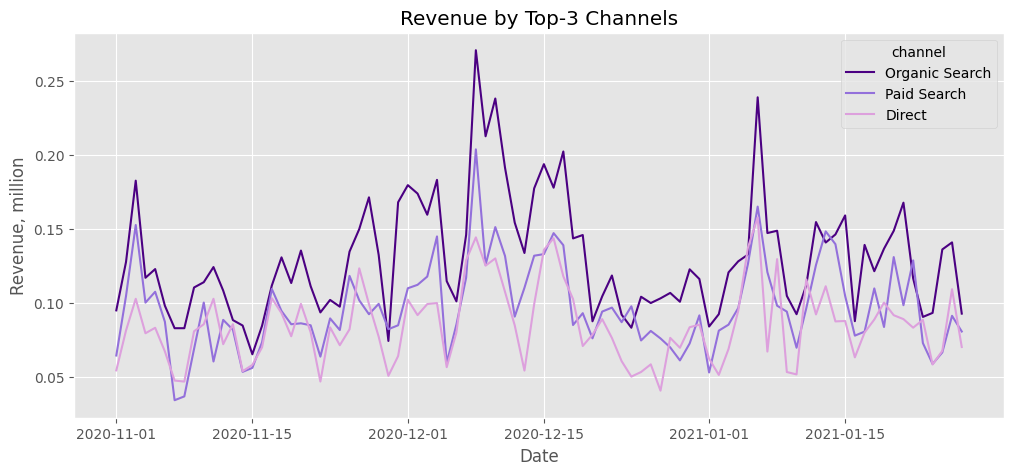

In [80]:
ch = df_top_ch.pivot_table(index='date', columns='channel', values='product_price', aggfunc='sum', fill_value=0) / 1000000
ch = ch[['Organic Search', 'Paid Search', 'Direct']]

plt.figure(figsize=(12, 5))
sns.lineplot(data=ch, dashes=False, palette=['indigo', 'mediumpurple', 'plum'])
plt.title('Revenue by Top-3 Channels')
plt.xlabel('Date')
plt.ylabel('Revenue, million')
plt.show()

Organic Search is the leading revenue driver, consistently outperforming other marketing channels throughout the period with clear spikes in revenue. Paid Search ranks second with a steady and predictable revenue stream. Direct traffic accounts for the smallest share, holding a low but stable position. Organic and paid search channels combined represent the foundation of total sales.

#Pivot Tables

##By top-10 categories and top-5 countries

In [81]:
grby_country = df.groupby('country')['product_price'].count().sort_values(ascending=False).head(5).reset_index()
top_countries = grby_country['country'].tolist()
top_countries

['United States', 'India', 'Canada', 'United Kingdom', 'France']

In [82]:
grby_category = df.groupby('product_category')['product_price'].count().sort_values(ascending=False).head(10).reset_index()
top_categories = grby_category['product_category'].tolist()
top_categories

['Bookcases & shelving units',
 'Chairs',
 'Sofas & armchairs',
 'Tables & desks',
 'Beds',
 'Cabinets & cupboards',
 'Outdoor furniture',
 "Children's furniture",
 'Chests of drawers & drawer units',
 'Bar furniture']

In [83]:
data_top = df[(df['country'].isin(top_countries)) & (df['product_category'].isin(top_categories))]

In [84]:
pt_cc = pd.pivot_table(data=data_top, index='country', columns='product_category', values='product_price', aggfunc='count', fill_value=0).reindex(index=top_countries, columns=top_categories)
pt_cc

product_category,Bookcases & shelving units,Chairs,Sofas & armchairs,Tables & desks,Beds,Cabinets & cupboards,Outdoor furniture,Children's furniture,Chests of drawers & drawer units,Bar furniture
country,,,,,,,,,,
United States,3374,2576,1903,1248,1298,995,984,752,616,487
India,734,539,396,287,236,201,183,142,129,96
Canada,591,450,331,219,218,184,177,116,113,83
United Kingdom,232,177,137,82,97,77,65,42,55,34
France,144,116,91,60,56,51,38,46,32,17


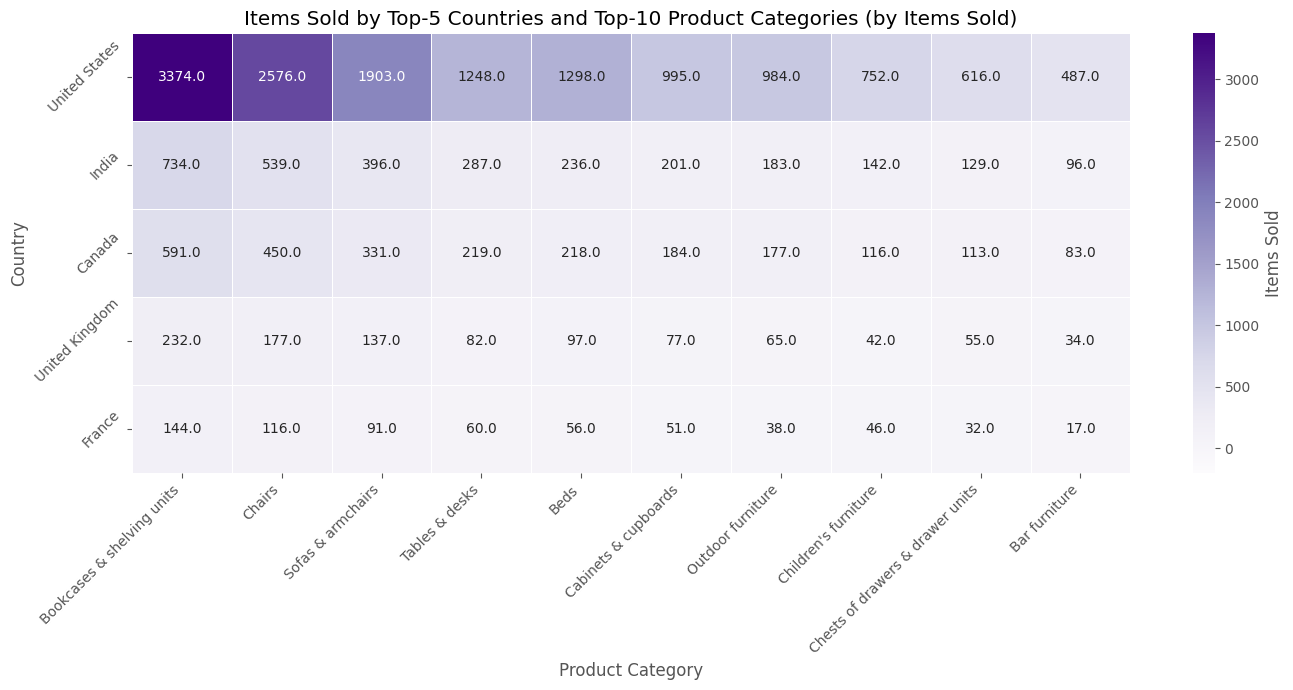

In [85]:
plt.figure(figsize=(14, 7))
sns.heatmap(data=pt_cc, annot=True, fmt='.1f', cmap='Purples', vmin=-200, linewidths=0.5, cbar_kws={'label': 'Items Sold'})
plt.title('Items Sold by Top-5 Countries and Top-10 Product Categories (by Items Sold)')
plt.xlabel('Product Category')
plt.ylabel('Country')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

The heat map visualizes the distribution of the number of items sold by the top 5 countries (United States, India, Canada, United Kingdom, France) and the top 10 product categories (excluding the abnormally large “Unknown” category—indicating no purchase—which was removed for clarity). The United States shows the highest figures in all product categories by a significant margin (for example, over 3,370 units were sold in the “Bookcases & Shelving Units” category). India and Canada hold second and third place, respectively, in terms of sales volume, while the United Kingdom and France have noticeably fewer items purchased. Regardless of the country, the categories “Bookcases & shelving units,” “Chairs,” and “Sofas & armchairs” are in the highest demand, while the lowest figures were recorded for the categories “Chests of drawers & drawer units” and “Bar furniture.”

##By Device and Channel

In [86]:
pt_dc = pd.pivot_table(data=df, index='device', columns='channel', values='product_price', aggfunc='count', fill_value=0)
pt_dc

channel,Direct,Organic Search,Other,Paid Search,Social Search
device,,,,,
desktop,4655,7011,1181,5261,1594
mobile,2985,4655,834,3574,1065
tablet,160,255,44,207,57


In [87]:
pt_dc = pt_dc.loc[pt_dc.sum(axis=1).sort_values(ascending=False).index,
                  pt_dc.sum(axis=0).sort_values(ascending=False).index]
pt_dc

channel,Organic Search,Paid Search,Direct,Social Search,Other
device,,,,,
desktop,7011,5261,4655,1594,1181
mobile,4655,3574,2985,1065,834
tablet,255,207,160,57,44


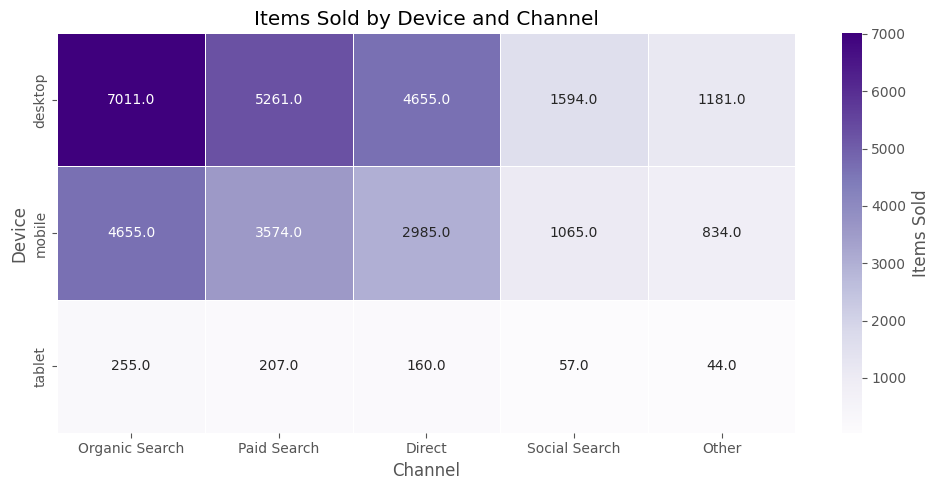

In [88]:
plt.figure(figsize=(10, 5))
sns.heatmap(data=pt_dc, annot=True, fmt='.1f', cmap='Purples', linewidths=0.5, cbar_kws={'label': 'Items Sold'})
plt.title('Items Sold by Device and Channel')
plt.xlabel('Channel')
plt.ylabel('Device')

plt.tight_layout()
plt.show()

The heat map visualizes the number of items sold by device (Desktop, Mobile, Tablet) and traffic channel (Direct, Organic Search, Other Channel, Paid Search, Social Search).
Desktop is the undisputed leader in terms of the number of purchases, generating the highest sales volumes across all channels. Mobile ranks second, while Tablet’s figures remain minimal.
Most Effective Channels: Organic Search and Paid Search drive the highest number of sales—these channels show the strongest performance on both desktops and mobile devices. Direct traffic also generates steady sales.
Least Active Channels: The “Other Channel” and “Social Search” channels show the lowest sales results across all device types.

##By Browser and Operating System

In [89]:
pt_bo = pd.pivot_table(data=df, index='browser', columns='operating_system', values='product_price', aggfunc='count', fill_value=0)
pt_bo

operating_system,Android,Macintosh,Other,Web,Windows,iOS
browser,,,,,,
Android Webview,99,0,0,321,0,0
Chrome,2526,1857,849,13993,3401,389
Edge,0,6,0,480,266,0
Firefox,10,49,24,362,138,0
Other,217,7,9,515,91,26
Safari,0,654,0,3866,0,3383


In [90]:
pt_bo = pt_bo.loc[pt_bo.sum(axis=1).sort_values(ascending=False).index,
                  pt_bo.sum(axis=0).sort_values(ascending=False).index]
pt_bo

operating_system,Web,Windows,iOS,Android,Macintosh,Other
browser,,,,,,
Chrome,13993,3401,389,2526,1857,849
Safari,3866,0,3383,0,654,0
Other,515,91,26,217,7,9
Edge,480,266,0,0,6,0
Firefox,362,138,0,10,49,24
Android Webview,321,0,0,99,0,0


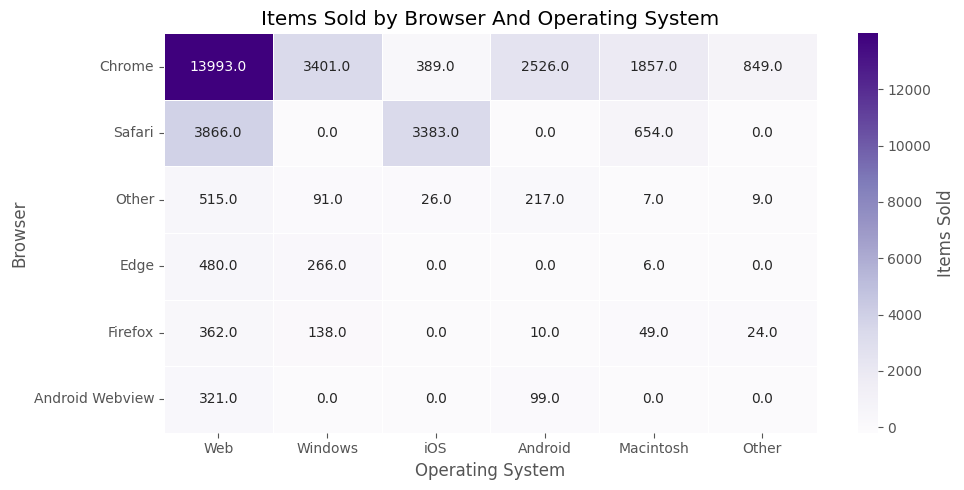

In [91]:
plt.figure(figsize=(10, 5))
sns.heatmap(data=pt_bo, annot=True, fmt='.1f', cmap='Purples', vmin=-200, linewidths=0.5, cbar_kws={'label': 'Items Sold'})
plt.title('Items Sold by Browser And Operating System')
plt.xlabel('Operating System')
plt.ylabel('Browser')

plt.tight_layout()
plt.show()

The heat map visualizes the number of items sold across different web browsers and operating systems. The highest sales volumes are clearly concentrated in the Chrome browser, particularly on Web platforms (over 13,900 units), Windows (over 3,400 units), Android (over 2,500 units), and Macintosh (over 1,800 units). Safari also shows significant sales activity, mainly driven by iOS (over 3,300 units) and Macintosh (over 600 units). Other browser and OS combinations, such as Edge, Firefox, and Android Webview, contribute minimal sales figures compared to the dominant leaders.

#Statistical Analysis of Correlations

##Revenue vs Session Count

In [92]:
groupby_date_clean = df_dt.groupby('date')[['session_id', 'product_price']].agg({'session_id': 'count', 'product_price': 'sum'}).reset_index()
groupby_date_clean['product_price'] = groupby_date_clean['product_price'] / 1000
groupby_date_clean.tail()

,date,session_id,product_price
83,2021-01-23,3067,290.6055
84,2021-01-24,2893,243.8184
85,2021-01-25,3760,305.0893
86,2021-01-26,3970,372.0573
87,2021-01-27,4435,286.3407


In [93]:
_, p_value_shapiro_session = shapiro(groupby_date_clean['session_id'])
print(f'P_value session_id: {p_value_shapiro_session}')

_, p_value_shapiro_price = shapiro(groupby_date_clean['product_price'])
print(f'P_value product_price: {p_value_shapiro_price}')

P_value session_id: 0.03948838648168485
P_value product_price: 0.004792566838665349


The Shapiro-Wilk test was applied to both metrics. For daily sessions the p-value is about 0.039, and for daily revenue about 0.005. Both are below the 0.05 significance level, so the hypothesis of a normal distribution is rejected for both variables. Because the normality assumption of the Pearson correlation is not met, we use the Spearman rank correlation, which does not require normally distributed data and is less sensitive to outliers.

In [94]:
print(f"Test statistic and p-value: {spearmanr(groupby_date_clean['session_id'], groupby_date_clean['product_price'])}")

Test statistic and p-value: SignificanceResult(statistic=np.float64(0.904283047444613), pvalue=np.float64(1.5381769633064087e-33))


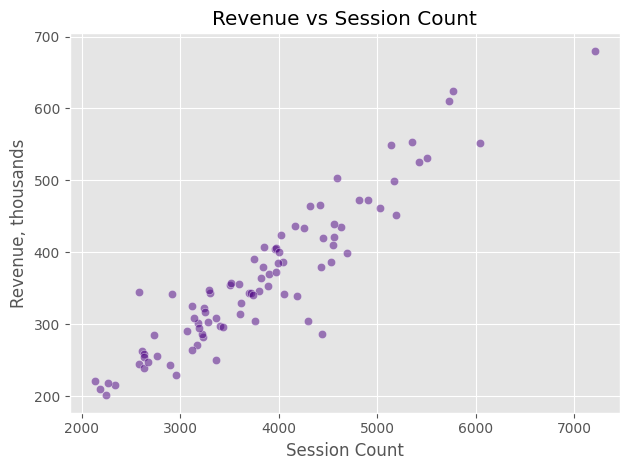

In [95]:
sns.scatterplot(data=groupby_date_clean, x="session_id", y="product_price", alpha=0.5, color='indigo')
plt.title("Revenue vs Session Count")
plt.xlabel("Session Count")
plt.ylabel("Revenue, thousands")

plt.tight_layout()
plt.show()

The scatter plot shows a clear positive correlation between the number of sessions and daily sales: days with more sessions generally generate higher revenue, and the data points form a fairly compact upward trend. The Spearman correlation coefficient is approximately 0.90, indicating a very strong positive monotonic relationship. The p-value is significantly less than 0.05; therefore, the correlation is statistically significant and cannot be attributed to chance.

##Top-3 Continents

**con** is already completed table, which was used for dynamic calculation.

In [96]:
con.tail()

continent,Americas,Asia,Europe
date,,,
2021-01-23,0.155343,0.068543,0.062884
2021-01-24,0.116989,0.074801,0.047535
2021-01-25,0.182548,0.066215,0.055621
2021-01-26,0.215973,0.077995,0.067143
2021-01-27,0.166736,0.066783,0.048156


In [97]:
_, p_value_shapiro_americas = shapiro(con['Americas'])
print(f'P_value Americas: {p_value_shapiro_americas}')

_, p_value_shapiro_asia = shapiro(con['Asia'])
print(f'P_value Asia: {p_value_shapiro_asia}')

_, p_value_shapiro_europe = shapiro(con['Europe'])
print(f'P_value Europe: {p_value_shapiro_europe}')

P_value Americas: 0.04246856262900114
P_value Asia: 0.0003820857396580045
P_value Europe: 0.007309892924070338


Since the p-values for all continents were significantly lower than the standard significance level, this means that the data do not follow a normal distribution. Therefore, Spearman’s correlation coefficient will be used for further correlation analysis.

In [98]:
print("Americas vs Asia:", spearmanr(con['Americas'], con['Asia']))
print("Americas vs Europe:", spearmanr(con['Americas'], con['Europe']))
print("Asia vs Europe:", spearmanr(con['Asia'], con['Europe']))

Americas vs Asia: SignificanceResult(statistic=np.float64(0.6685393258426968), pvalue=np.float64(1.1001059722381636e-12))
Americas vs Europe: SignificanceResult(statistic=np.float64(0.6258849635447854), pvalue=np.float64(7.009052955139405e-11))
Asia vs Europe: SignificanceResult(statistic=np.float64(0.6082209150787222), pvalue=np.float64(3.2731384105062476e-10))


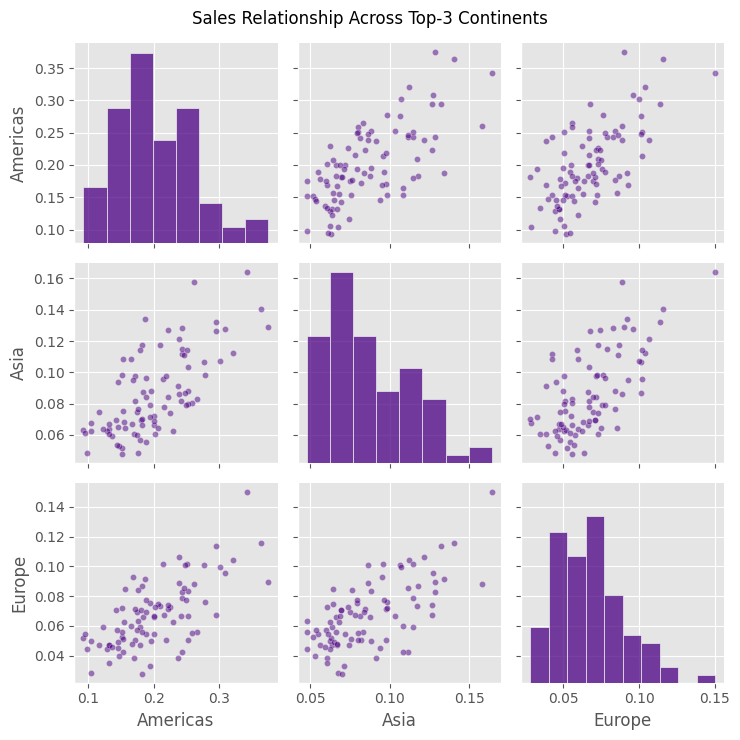

In [99]:
g = sns.pairplot(con, plot_kws={'color': 'indigo', 'alpha': 0.5, 's': 20}, diag_kws={'color': 'indigo'})
g.fig.suptitle('Sales Relationship Across Top-3 Continents')

plt.tight_layout()
plt.show()

Based on an analysis of the relationship between sales across the top three continents (the Americas, Asia, and Europe) using Spearman’s rank correlation, the following was found: All pairs of continents exhibit a noticeable positive correlation with a high level of statistical significance. A correlation coefficient is observed between the Americas and Asia, as well as between the Americas and Europe, and between Asia and Europe. Scatter plots confirm the presence of common trends in sales dynamics across regions, indicating general global trends in market demand.

##Devices

**dev** is already completed table, which was used for dynamic calculation.

In [100]:
dev.tail()

device,desktop,mobile,tablet
date,,,
2021-01-23,0.174769,0.115462,0.000374
2021-01-24,0.147218,0.093233,0.003367
2021-01-25,0.189442,0.107903,0.007745
2021-01-26,0.207834,0.162898,0.001325
2021-01-27,0.173454,0.102042,0.010845


In [101]:
_, p_value_shapiro_desktop = shapiro(dev['desktop'])
print(f'P_value Desktop: {p_value_shapiro_desktop}')

_, p_value_shapiro_mobile = shapiro(dev['mobile'])
print(f'P_value Mobile: {p_value_shapiro_mobile}')

_, p_value_shapiro_tablet = shapiro(dev['tablet'])
print(f'P_value Tablet: {p_value_shapiro_tablet}')

P_value Desktop: 0.014953922836652082
P_value Mobile: 0.001383327321967185
P_value Tablet: 0.000300223199948774


Since the p-values for all device types were significantly lower than the standard significance level, this means that the data do not follow a normal distribution. Therefore, Spearman’s correlation coefficient will be used for further correlation analysis.

In [102]:
print("Desktop vs Mobile:", spearmanr(dev['desktop'], dev['mobile']))
print("Desktop vs Tablet:", spearmanr(dev['desktop'], dev['tablet']))
print("Mobile vs Tablet:", spearmanr(dev['mobile'], dev['tablet']))

Desktop vs Mobile: SignificanceResult(statistic=np.float64(0.7702088690077843), pvalue=np.float64(1.7614974818574937e-18))
Desktop vs Tablet: SignificanceResult(statistic=np.float64(0.3902750443622254), pvalue=np.float64(0.0001706113882612224))
Mobile vs Tablet: SignificanceResult(statistic=np.float64(0.4014317980728127), pvalue=np.float64(0.00010606064101142727))


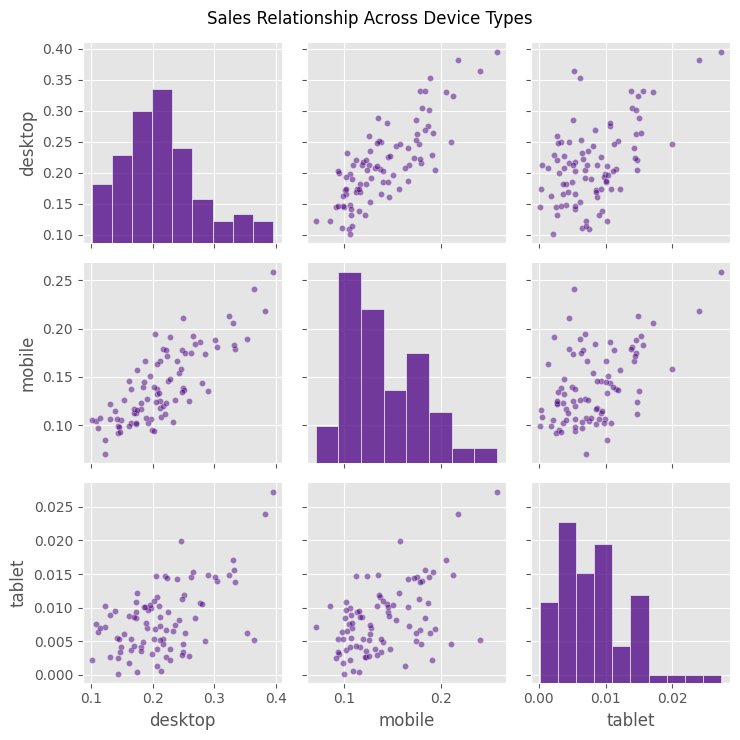

In [103]:
h = sns.pairplot(dev, plot_kws={'color': 'indigo', 'alpha': 0.5, 's': 20}, diag_kws={'color': 'indigo'})
h.fig.suptitle('Sales Relationship Across Device Types')

plt.tight_layout()
plt.show()

The highest level of correlation and statistical significance is observed between desktop and mobile (a correlation coefficient of 0.70 with an extremely low p-value), indicating synchrony in user behavior across these platforms (an increase in activity on PCs is accompanied by an increase on mobile devices). The correlation with tablets is weaker: The pairs “desktop vs. tablet” and “mobile vs. tablet” show a weaker correlation and more scattered scatter plots on the graphs.

##Top-3 Channels

**ch** is already completed table, which was used for dynamic calculation.

In [104]:
ch.tail()

channel,Organic Search,Paid Search,Direct
date,,,
2021-01-23,0.090686,0.073075,0.088714
2021-01-24,0.093414,0.059018,0.058644
2021-01-25,0.136179,0.066776,0.067844
2021-01-26,0.140921,0.091438,0.109356
2021-01-27,0.092921,0.080869,0.070423


In [105]:
_, p_value_shapiro_os = shapiro(ch['Organic Search'])
print(f'P_value Organic Search: {p_value_shapiro_os}')

_, p_value_shapiro_ps = shapiro(ch['Paid Search'])
print(f'P_value Paid Search: {p_value_shapiro_ps}')

_, p_value_shapiro_d = shapiro(ch['Direct'])
print(f'P_value Direct: {p_value_shapiro_d}')

P_value Organic Search: 9.599991143695942e-05
P_value Paid Search: 0.01743584767620841
P_value Direct: 0.012486076318203962


Since the p-values for all channels were significantly lower than the standard significance level, this means that the data do not follow a normal distribution. Therefore, Spearman’s correlation coefficient will be used for further correlation analysis.

In [106]:
print("Organic Search vs Paid Search:", spearmanr(ch['Organic Search'], ch['Paid Search']))
print("Organic Search vs Direct:", spearmanr(ch['Organic Search'], ch['Direct']))
print("Paid Search vs Direct:", spearmanr(ch['Paid Search'], ch['Direct']))

Organic Search vs Paid Search: SignificanceResult(statistic=np.float64(0.7639216653164737), pvalue=np.float64(4.8634931780185696e-18))
Organic Search vs Direct: SignificanceResult(statistic=np.float64(0.7482476841252511), pvalue=np.float64(5.362547239818307e-17))
Paid Search vs Direct: SignificanceResult(statistic=np.float64(0.6907822901623755), pvalue=np.float64(9.505458925584083e-14))


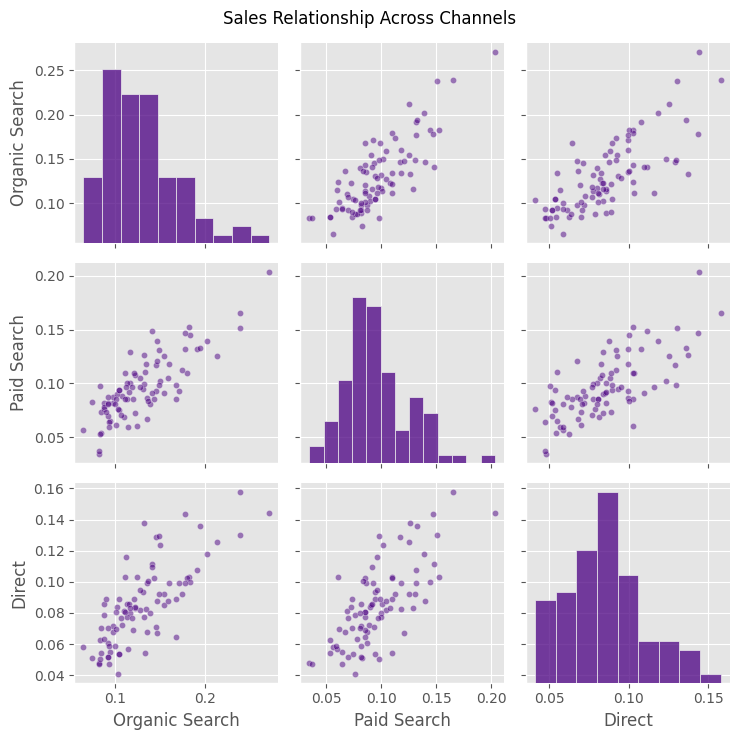

In [107]:
t = sns.pairplot(ch, plot_kws={'color': 'indigo', 'alpha': 0.5, 's': 20}, diag_kws={'color': 'indigo'})
t.fig.suptitle('Sales Relationship Across Channels')

plt.tight_layout()
plt.show()

All traffic channels (Organic Search, Paid Search, Direct) show a strong Spearman’s correlation (ranging from 0.69 to 0.76), indicating synchrony in user acquisition. Such a low p-value ensures that the identified relationship is entirely systematic and statistically significant, rather than a random coincidence or data error.

##Top-3 Operating System

**op** is already completed table, which was used for dynamic calculation.

In [108]:
op.tail()

operating_system,Web,Windows,iOS
date,,,
2021-01-23,0.176337,0.038406,0.025201
2021-01-24,0.124780,0.036154,0.024704
2021-01-25,0.187699,0.033275,0.034203
2021-01-26,0.201619,0.038969,0.040115
2021-01-27,0.160511,0.028811,0.037724


In [109]:
_, p_value_shapiro_web = shapiro(op['Web'])
print(f'P_value Web: {p_value_shapiro_web}')

_, p_value_shapiro_windows = shapiro(op['Windows'])
print(f'P_value Windows: {p_value_shapiro_windows}')

_, p_value_shapiro_ios = shapiro(op['iOS'])
print(f'P_value iOS: {p_value_shapiro_ios}')

P_value Web: 0.003236750276301253
P_value Windows: 0.004300726445400989
P_value iOS: 0.007916733695171948


Since the p-values for all operating systems were significantly lower than the standard significance level, this means that the data do not follow a normal distribution. Therefore, Spearman’s correlation coefficient will be used for further correlation analysis.

In [110]:
print("Web vs Windows:", spearmanr(op['Web'], op['Windows']))
print("Web vs iOS:", spearmanr(op['Web'], op['iOS']))
print("Windows vs iOS:", spearmanr(op['Windows'], op['iOS']))

Web vs Windows: SignificanceResult(statistic=np.float64(0.7030044732485649), pvalue=np.float64(2.2494701621836837e-14))
Web vs iOS: SignificanceResult(statistic=np.float64(0.687911662146455), pvalue=np.float64(1.319877940993155e-13))
Windows vs iOS: SignificanceResult(statistic=np.float64(0.5750061639251877), pvalue=np.float64(4.6543764988963714e-09))


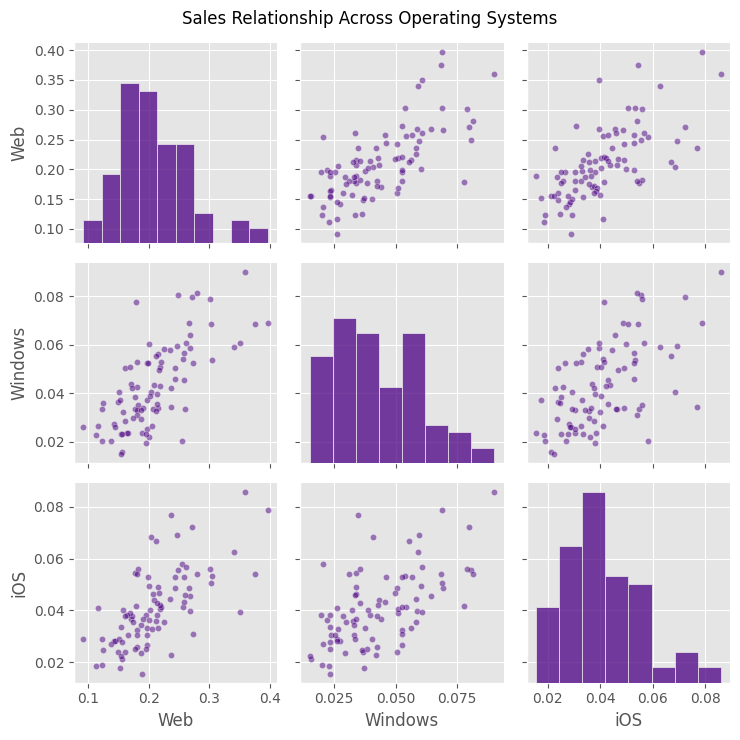

In [111]:
c = sns.pairplot(op, plot_kws={'color': 'indigo', 'alpha': 0.5, 's': 20}, diag_kws={'color': 'indigo'})
c.fig.suptitle('Sales Relationship Across Operating Systems')

plt.tight_layout()
plt.show()

All pairs of operating systems (Web vs. Windows, Web vs. iOS, Windows vs. iOS) show a high Spearman’s correlation (ranging from 0.58 to 0.78), reflecting common trends in user activity across these platforms. Such a low p-value confirms that the identified relationship is entirely systematic and statistically significant, rather than a random coincidence in the data.

#Statistical Analysis of Differences Between Groups

##Registered vs Not Registered Users

Now we will carry out a statistical analysis of the differences in daily revenue per session between registered and unregistered users.

In [112]:
reg_daily = (
    df_dt[df_dt['registered_user_id'] != 'Guest']
    .groupby('date')
    .agg(total_revenue=('product_price', 'sum'), sessions=('session_id', 'count'))
.reset_index()
)
reg_daily['avg_revenue'] = reg_daily['total_revenue'] / reg_daily['sessions']
reg_daily.head()

,date,total_revenue,sessions,avg_revenue
0,2020-11-01,21547.0,231,93.277056
1,2020-11-02,44956.8,298,150.861745
2,2020-11-03,29150.5,451,64.635255
3,2020-11-04,20982.2,337,62.261721
4,2020-11-05,25334.6,305,83.064262


In [113]:
unreg_daily = (
    df_dt[df_dt['registered_user_id'] == 'Guest']
    .groupby('date')
    .agg(total_revenue=('product_price', 'sum'), sessions=('session_id', 'count'))
.reset_index()
)
unreg_daily['avg_revenue'] = unreg_daily['total_revenue'] / unreg_daily['sessions']
unreg_daily.head()

,date,total_revenue,sessions,avg_revenue
0,2020-11-01,222745.5,2345,94.98742
1,2020-11-02,310550.0,3301,94.077552
2,2020-11-03,469829.1,4722,99.497903
3,2020-11-04,318204.9,3847,82.715077
4,2020-11-05,365942.0,3438,106.440372


In [114]:
merged_df = pd.merge(
    reg_daily[['date', 'avg_revenue']],
    unreg_daily[['date', 'avg_revenue']],
    on='date',
    suffixes=('_registered', '_unregistered'),
).dropna()
merged_df.head()

,date,avg_revenue_registered,avg_revenue_unregistered
0,2020-11-01,93.277056,94.98742
1,2020-11-02,150.861745,94.077552
2,2020-11-03,64.635255,99.497903
3,2020-11-04,62.261721,82.715077
4,2020-11-05,83.064262,106.440372


In [115]:
p_val_reg = shapiro(merged_df['avg_revenue_registered']).pvalue
p_val_unreg = shapiro(merged_df['avg_revenue_unregistered']).pvalue
print(f'P-value Shapiro (Registered): {p_val_reg}')
print(f'P-value Shapiro (Unregistered): {p_val_unreg}')

P-value Shapiro (Registered): 0.002769950100124018
P-value Shapiro (Unregistered): 0.23970108782881028


In [116]:
_, p_value_wilcoxon = wilcoxon(merged_df['avg_revenue_registered'], merged_df['avg_revenue_unregistered'])
print(f'Wilcoxon test p-value: {p_value_wilcoxon}')

Wilcoxon test p-value: 0.13415714701618797


After creating two paired samples based on daily revenue per session for registered and unregistered users, we checked their distributions using the Shapiro-Wilk test. The p-value for registered users is approximately 0.003, which is below the 0.05 significance level, rejecting the hypothesis of a normal distribution. For unregistered users, the p-value is approximately 0.240, indicating a distribution closer to normal. Since one of the samples violates the normality assumption, a non-parametric test is required. Because the daily metrics represent paired observations matched by date, we applied the non-parametric paired Wilcoxon signed-rank test. The resulting p-value of approximately 0.134 is well above the 0.05 threshold, indicating that there is no statistically significant difference in average daily revenue per session between registered and unregistered users.

##Channels

Now we analyze the number of sessions across different traffic channels.

In [117]:
channel_pv = df_dt.pivot_table(index='date', columns='channel', values='session_id', aggfunc='count', fill_value=0)
channel_pv.head()

channel,Direct,Organic Search,Other,Paid Search,Social Search
date,,,,,
2020-11-01,608,920,128,706,214
2020-11-02,810,1242,262,970,315
2020-11-03,1216,1871,327,1367,392
2020-11-04,935,1425,311,1145,368
2020-11-05,845,1293,342,917,346


In [118]:
_, p_value_shapiro_dir = shapiro(channel_pv['Direct'])
print(f'P_value Direct: {p_value_shapiro_dir}')

_, p_value_shapiro_ors = shapiro(channel_pv['Organic Search'])
print(f'P_value Organic Search: {p_value_shapiro_ors}')

_, p_value_shapiro_oth = shapiro(channel_pv['Other'])
print(f'P_value Other: {p_value_shapiro_oth}')

_, p_value_shapiro_psr = shapiro(channel_pv['Paid Search'])
print(f'P_value Paid Search: {p_value_shapiro_psr}')

_, p_value_shapiro_ss = shapiro(channel_pv['Social Search'])
print(f'P_value Social Search: {p_value_shapiro_ss}')


P_value Direct: 0.04684284582084014
P_value Organic Search: 0.02322342693371155
P_value Other: 0.058871751035083054
P_value Paid Search: 0.016535898889849687
P_value Social Search: 0.17740370840264302


The Shapiro-Wilk test was applied to the daily session counts of each traffic channel. For Direct (p ≈ 0.047), Organic Search (p ≈ 0.023) and Paid Search (p ≈ 0.017) the p-values are below 0.05, so the hypothesis of a normal distribution is rejected for these channels. For Other (p ≈ 0.059) and Social Search (p ≈ 0.177) the p-values are above 0.05, so normality is not rejected, although the result for Other is borderline. Since at least one channel (in fact, three of five) deviates from normality, the assumptions of ANOVA are not met for the whole set of groups. Therefore, to compare the number of sessions across the channels we use the non-parametric Kruskal-Wallis test, which does not require normally distributed data.

In [119]:
_, p_value_k = kruskal(channel_pv['Direct'], channel_pv['Organic Search'], channel_pv['Other'], channel_pv['Paid Search'], channel_pv['Social Search'])

print(f"P-value: {p_value_k}")

P-value: 5.186401227135924e-75


The Kruskal-Wallis test gave a p-value of about 5.2e-75, which is far below the 0.05 significance level. We therefore reject the null hypothesis that the daily session counts come from the same distribution in all channels: there are statistically significant differences in the number of sessions between at least some of the traffic channels. The Kruskal-Wallis test shows only that the channels differ overall, but not which specific pairs differ.

##Devices


Now we analyze the number of sessions across different devices.

In [120]:
device_pv = df_dt.pivot_table(index='date', columns='device', values='session_id', aggfunc='count', fill_value=0)
device_pv.head()

device,desktop,mobile,tablet
date,,,
2020-11-01,1505,1022,49
2020-11-02,2102,1427,70
2020-11-03,3016,2050,107
2020-11-04,2469,1597,118
2020-11-05,2147,1506,90


In [121]:
_, p_value_shapiro_desk = shapiro(device_pv['desktop'])
print(f'P_value desktop: {p_value_shapiro_desk}')

_, p_value_shapiro_mob = shapiro(device_pv['mobile'])
print(f'P_value mobile: {p_value_shapiro_mob}')

_, p_value_shapiro_tab = shapiro(device_pv['tablet'])
print(f'P_value tablet: {p_value_shapiro_tab}')

P_value desktop: 0.016847522596788487
P_value mobile: 0.11618938779988808
P_value tablet: 0.08910287349103804


For desktop the p-value is about 0.017, which is below 0.05, so the hypothesis of a normal distribution is rejected. For mobile (p ≈ 0.116) and tablet (p ≈ 0.089) the p-values are above 0.05, so normality is not rejected for these devices. Since at least one group deviates from normality, the assumptions of ANOVA are not met for the whole set of groups. Therefore, to compare the number of sessions across the device types we use the non-parametric Kruskal-Wallis test, which does not require normally distributed data.

In [122]:
_, p_value_k_d = kruskal(device_pv['desktop'], device_pv['mobile'], device_pv['tablet'])

print(f"P-value: {p_value_k_d}")

P-value: 1.1594731205001205e-45


The Kruskal-Wallis test gave a p-value is far below the 0.05 significance level. There are statistically significant differences in the number of sessions between the devices. The test shows only that the devices differ overall, but not which specific pairs differ.

##Share of sessions with organic traffic Europe vs Americas

Now we check whether the share of sessions with organic traffic differs statistically between Europe and the Americas. Since we compare proportions of two independent groups, we first calculate the input data for the test: for each continent, the total number of sessions and the number of sessions that came from organic search.

In [123]:
eu_org_session = df[(df['continent'] == 'Europe') & (df['channel'] == 'Organic Search')]['session_id'].count()
eu_session = df[df['continent'] == 'Europe']['session_id'].count()

In [124]:
am_org_session = df[(df['continent'] == 'Americas') & (df['channel'] == 'Organic Search')]['session_id'].count()
am_session = df[df['continent'] == 'Americas']['session_id'].count()

In [125]:
_, p_value_share = sm.stats.proportions_ztest([eu_org_session, am_org_session], [eu_session, am_session])

print(f"P-value: {p_value_share}")

P-value: 0.7721879690501752


To compare the share of sessions with organic traffic in Europe and the Americas, we used the two-proportion z-test, since we compare proportions in two independent groups with large sample sizes. The p-value is about 0.77, which is much higher than the 0.05 significance level. Therefore, there is no statistically significant difference between the share of organic sessions in Europe and in the Americas.

##Share of sessions with paid traffic United States vs Canada

Now we check whether the share of sessions with paid traffic differs statistically between United States and Canada.

In [126]:
us_paid_session = df[(df['country'] == 'United States') & (df['channel'] == 'Paid Search')]['session_id'].count()
us_session = df[df['country'] == 'United States']['session_id'].count()

can_paid_session = df[(df['country'] == 'Canada') & (df['channel'] == 'Paid Search')]['session_id'].count()
can_session = df[df['country'] == 'Canada']['session_id'].count()

In [127]:
_, p_value_share_country = sm.stats.proportions_ztest([us_paid_session, can_paid_session], [us_session, can_session])

print(f"P-value: {p_value_share_country}")

P-value: 0.944160809594007


We used the two-proportion z-test for two independent groups with large samples. The p-value is about 0.94, which is far above the 0.05 significance level. Therefore, we fail to reject the null hypothesis: there is no statistically significant difference between the share of sessions with paid traffic in the United States and in Canada. In other words, paid search brings a very similar share of sessions in both countries, and the small difference in the observed shares can be explained by chance.

#Summary

Over the three months covered by the dataset, sales appear to depend heavily on a few markets: the United States is by far the largest one, the Americas generate much more revenue than Asia and Europe, and India and Canada come next, while the United Kingdom and France contribute noticeably less. In terms of product categories, revenue is heavily concentrated in top categories, led by “Sofas & armchairs” and “Chairs”, followed by “Beds” and “Bookcases & shelving units”.

Most purchases are made from desktop devices, mobile comes second and tablets play only a minor role, and organic and paid search seem to be the main sales channels, followed by direct traffic. Demand follows a weekly pattern, with the strongest sales on Tuesday and Wednesday and the weakest at weekends, and revenue also peaks in December and early January, which may be connected to the holiday shopping season, although with only three months of data we can only speak about a weekly cycle rather than confirmed long-term seasonality.

Days with more sessions bring more revenue, and sales in different continents, channels, devices and operating systems tend to rise and fall together, which may point to shared demand factors rather than independent regional trends. Statistical tests show that the number of sessions differs between channels and between devices, while the share of organic traffic looks similar in Europe and the Americas and the share of paid traffic looks similar in the United States and Canada. At the same time, the paired Wilcoxon test indicates no statistically significant difference in daily revenue per session between registered and unregistered users. Most visitors are guests who bring most of the revenue, but the small group of registered users looks highly engaged, with 71.7% having verified their accounts and 83.1% maintaining an active subscription status.

Based on these observations, several directions could be worth considering, ideally after further validation. The company might consider reducing its dependence on the United States and the Americas by exploring growth in the next largest markets, India and Canada, since a heavy reliance on one region can be a risk. It could also be beneficial to focus marketing and inventory on top-performing categories (Sofas & armchairs, Chairs) while reviewing the strategy for low-performing ones. It may be worth keeping search a priority by continuing to support SEO and paid search and by paying attention to the desktop and Chrome experience, since this is where most sales currently come from. It could be useful to review the mobile purchase path, because mobile brings a large share of traffic but appears to be the weaker platform. Increasing the number of registered users, for example through sign-up incentives or a newsletter, could be an option, since registered users appear to be engaged and may become returning customers.

#Analytics Dashboard
https://public.tableau.com/app/profile/nastasiia.nelina/viz/AnalyticsDashboard_17930397692660/AnalyticsDashboard?publish=yes